
# Model X — Neighborhood Livability Scoring Engine

**Version:** 0.1  
**Project:** Model X  
**Methodology:** Equal-weighted Composite Scoring Model  
**Primary Objective:** Evaluate neighborhood livability using measurable environmental, social and infrastructural indicators.

## Assessment Categories

1. Education
2. Healthcare
3. Public Safety
4. Air Quality
5. Water Availability
6. Electricity Reliability
7. Transportation Accessibility
8. Green-space Availability

## Scoring Methodology

- 16 input features.
- 8 assessment categories.
- 2 features per category.
- Equal weighting within categories.
- Equal weighting across all categories.
- Normalized scores ranging from 0 to 100.

## Expected Output

- Overall neighborhood livability score.
- Eight individual category scores.
- Comparative neighborhood assessment.

**Note:** Initial experiments use synthetic data and provisional normalization boundaries.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Model X - Composite Scoring Engine")


Model X - Composite Scoring Engine


In [5]:

# ============================================================
# 1. FEATURE CONFIGURATION
# Neighborhood Intelligence System
# ============================================================

FEATURE_CONFIG = {

    # -------------------- EDUCATION --------------------
    "school_density": {
        "category": "Education",
        "min": 0,
        "max": 10,
        "direction": "higher"
    },

    "school_distance_km": {
        "category": "Education",
        "min": 0,
        "max": 5,
        "direction": "lower"
    },

    # -------------------- HEALTHCARE --------------------
    "hospital_density": {
        "category": "Healthcare",
        "min": 0,
        "max": 5,
        "direction": "higher"
    },

    "hospital_distance_km": {
        "category": "Healthcare",
        "min": 0,
        "max": 10,
        "direction": "lower"
    },

    # -------------------- SAFETY --------------------
    "crime_rate": {
        "category": "Safety",
        "min": 0,
        "max": 100,
        "direction": "lower"
    },

    "crime_trend_pct": {
        "category": "Safety",
        "min": -50,
        "max": 100,
        "direction": "lower"
    },

    # -------------------- AIR QUALITY --------------------
    "average_aqi": {
        "category": "Air Quality",
        "min": 0,
        "max": 500,
        "direction": "lower"
    },

    "poor_air_days": {
        "category": "Air Quality",
        "min": 0,
        "max": 365,
        "direction": "lower"
    },

    # -------------------- WATER --------------------
    "water_supply_days": {
        "category": "Water",
        "min": 0,
        "max": 7,
        "direction": "higher"
    },

    "water_interruptions": {
        "category": "Water",
        "min": 0,
        "max": 30,
        "direction": "lower"
    },

    # -------------------- ELECTRICITY --------------------
    "power_outages": {
        "category": "Electricity",
        "min": 0,
        "max": 30,
        "direction": "lower"
    },

    "power_outage_hours": {
        "category": "Electricity",
        "min": 0,
        "max": 100,
        "direction": "lower"
    },

    # -------------------- TRANSPORT --------------------
    "bus_stop_density": {
        "category": "Transport",
        "min": 0,
        "max": 10,
        "direction": "higher"
    },

    "transit_distance_km": {
        "category": "Transport",
        "min": 0,
        "max": 2,
        "direction": "lower"
    },

    # -------------------- GREEN SPACE --------------------
    "green_coverage_pct": {
        "category": "Green Space",
        "min": 0,
        "max": 100,
        "direction": "higher"
    },

    "green_space_per_capita": {
        "category": "Green Space",
        "min": 0,
        "max": 50,
        "direction": "higher"
    }
}


# -------------------- CONFIGURATION VALIDATION --------------------

total_features = len(FEATURE_CONFIG)

total_categories = len({
    config["category"]
    for config in FEATURE_CONFIG.values()
})

for feature, config in FEATURE_CONFIG.items():

    assert config["min"] < config["max"], (
        f"Invalid range for {feature}"
    )

    assert config["direction"] in ["higher", "lower"], (
        f"Invalid direction for {feature}"
    )

    assert "category" in config, (
        f"Missing category for {feature}"
    )

print("FEATURE CONFIGURATION VALIDATED")
print("--------------------------------")
print(f"Total Features   : {total_features}")
print(f"Total Categories : {total_categories}")
print("Configuration Status: VALID")


FEATURE CONFIGURATION VALIDATED
--------------------------------
Total Features   : 16
Total Categories : 8
Configuration Status: VALID


In [6]:

# 2. SYNTHETIC DATASET GENERATION
import pandas as pd
import numpy as np

np.random.seed(42)
n_neighborhoods = 20

neighborhoods = [
    f"Neighborhood_{i+1:02d}"
    for i in range(n_neighborhoods)
]

synthetic_data = {
    "neighborhood_id": [
        f"NBH_{i+1:03d}" for i in range(n_neighborhoods)
    ],
    "neighborhood_name": neighborhoods,
    "assessment_period": ["2026-Q4"] * n_neighborhoods,
    "data_source": ["Synthetic"] * n_neighborhoods
}

integer_features = [
    "poor_air_days",
    "water_supply_days",
    "water_interruptions",
    "power_outages"
]

for feature, config in FEATURE_CONFIG.items():

    minimum = config["min"]
    maximum = config["max"]

    if feature in integer_features:
        values = np.random.randint(
            minimum,
            maximum + 1,
            size=n_neighborhoods
        )
    else:
        values = np.random.uniform(
            minimum,
            maximum,
            size=n_neighborhoods
        )

    synthetic_data[feature] = np.round(values).astype(int)

df = pd.DataFrame(synthetic_data)

display(df)

print("Dataset shape:", df.shape)
print("Total neighborhoods:", len(df))


,neighborhood_id,neighborhood_name,assessment_period,data_source,school_density,school_distance_km,hospital_density,hospital_distance_km,crime_rate,crime_trend_pct,average_aqi,poor_air_days,water_supply_days,water_interruptions,power_outages,power_outage_hours,bus_stop_density,transit_distance_km,green_coverage_pct,green_space_per_capita
0,NBH_001,Neighborhood_01,2026-Q4,Synthetic,4,3,1,4,86,-45,404,51,1,30,19,23,6,1,95,16
1,NBH_002,Neighborhood_02,2026-Q4,Synthetic,10,1,2,3,62,45,448,267,7,15,6,17,4,1,33,42
2,NBH_003,Neighborhood_03,2026-Q4,Synthetic,7,1,0,8,33,-3,159,294,5,15,19,98,9,2,55,7
3,NBH_004,Neighborhood_04,2026-Q4,Synthetic,6,2,5,4,6,26,55,112,7,0,8,52,10,1,57,35
4,NBH_005,Neighborhood_05,2026-Q4,Synthetic,2,2,1,3,31,86,114,100,6,8,0,26,3,2,98,28
5,NBH_006,Neighborhood_06,2026-Q4,Synthetic,2,4,3,5,33,-13,214,112,3,27,7,100,3,1,8,15
6,NBH_007,Neighborhood_07,2026-Q4,Synthetic,1,1,2,1,73,12,409,80,6,26,6,97,5,1,31,21
7,NBH_008,Neighborhood_08,2026-Q4,Synthetic,9,3,3,8,64,63,430,186,2,5,17,56,4,1,19,13
8,NBH_009,Neighborhood_09,2026-Q4,Synthetic,6,3,3,1,89,-16,3,112,7,15,7,88,10,1,27,31
9,NBH_010,Neighborhood_10,2026-Q4,Synthetic,7,0,1,10,47,-38,255,1,2,28,0,19,2,2,49,4


Dataset shape: (20, 20)
Total neighborhoods: 20


In [7]:

def normalize_dataset(data, feature_config):

    normalized_data = data.copy()

    for feature, config in feature_config.items():

        minimum = config["min"]
        maximum = config["max"]
        direction = config["direction"]

        values = data[feature]

        if maximum == minimum:
            raise ValueError(
                f"Invalid range for feature: {feature}"
            )

        if direction == "higher":

            score = (
                (values - minimum) /
                (maximum - minimum)
            ) * 100

        elif direction == "lower":

            score = (
                (maximum - values) /
                (maximum - minimum)
            ) * 100

        else:
            raise ValueError(
                f"Invalid direction for feature: {feature}"
            )

        normalized_data[feature + "_normalized"] = score.round(1)

    return normalized_data


normalized_df = normalize_dataset(df, FEATURE_CONFIG)



In [8]:
def aggregate_categories(data, feature_config):

    category_scores = data[
        ["neighborhood_id", "neighborhood_name"]
    ].copy()

    categories = set(
        config["category"]
        for config in feature_config.values()
    )

    for category in categories:

        category_features = [
            feature
            for feature, config in feature_config.items()
            if config["category"] == category
        ]

        normalized_columns = [
            feature + "_normalized"
            for feature in category_features
        ]

        category_scores[category + "_score"] = (
            data[normalized_columns]
            .mean(axis=1)
            .round(1)
        )

    return category_scores


category_df = aggregate_categories(
    normalized_df,
    FEATURE_CONFIG
)

def calculate_overall_score(category_data):

    overall_scores = category_data.copy()

    category_columns = [
        col for col in overall_scores.columns
        if col.endswith("_score")
    ]

    overall_scores["overall_score"] = (
        overall_scores[category_columns]
        .mean(axis=1)
        .round(1)
    )

    overall_scores["rank"] = (
        overall_scores["overall_score"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    overall_scores = overall_scores.sort_values(
        by="overall_score",
        ascending=False
    ).reset_index(drop=True)

    return overall_scores


final_scores_df = calculate_overall_score(category_df)


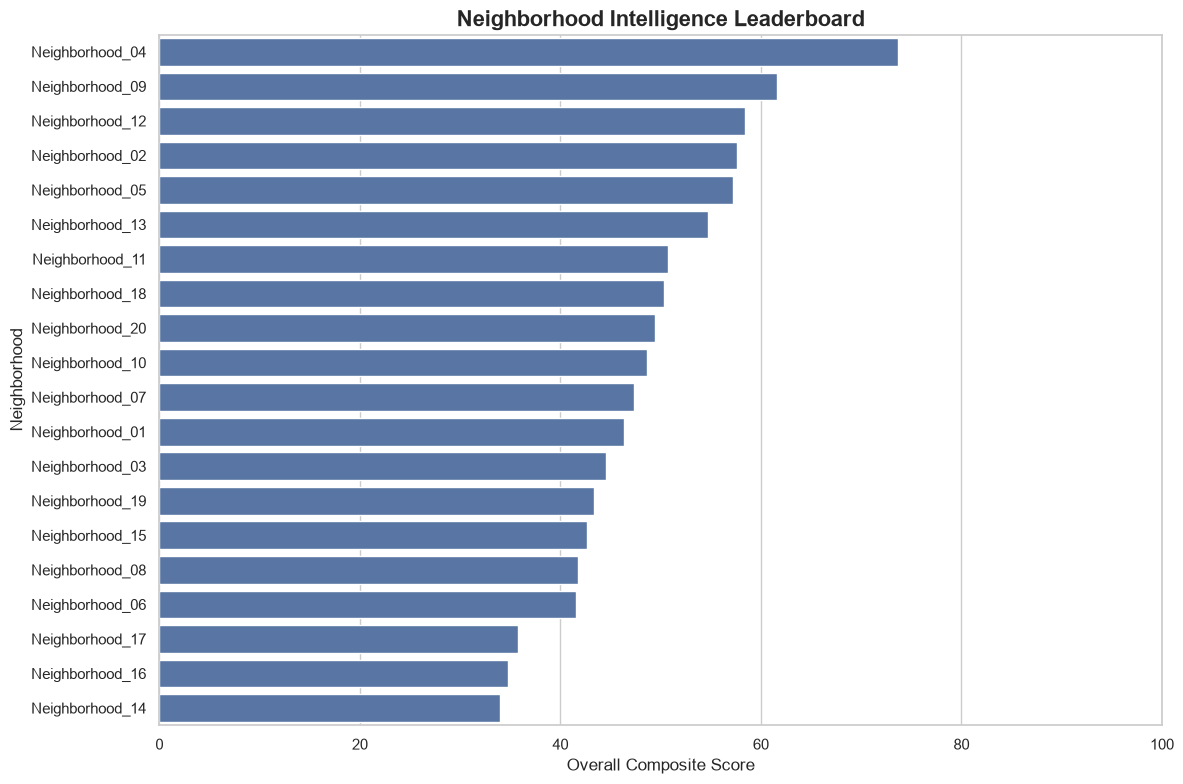

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 8))

sns.barplot(
    data=final_scores_df,
    x="overall_score",
    y="neighborhood_name"
)

plt.title(
    "Neighborhood Intelligence Leaderboard",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Overall Composite Score")
plt.ylabel("Neighborhood")
plt.xlim(0, 100)
plt.tight_layout()

plt.savefig(
    "screenshots/leaderboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



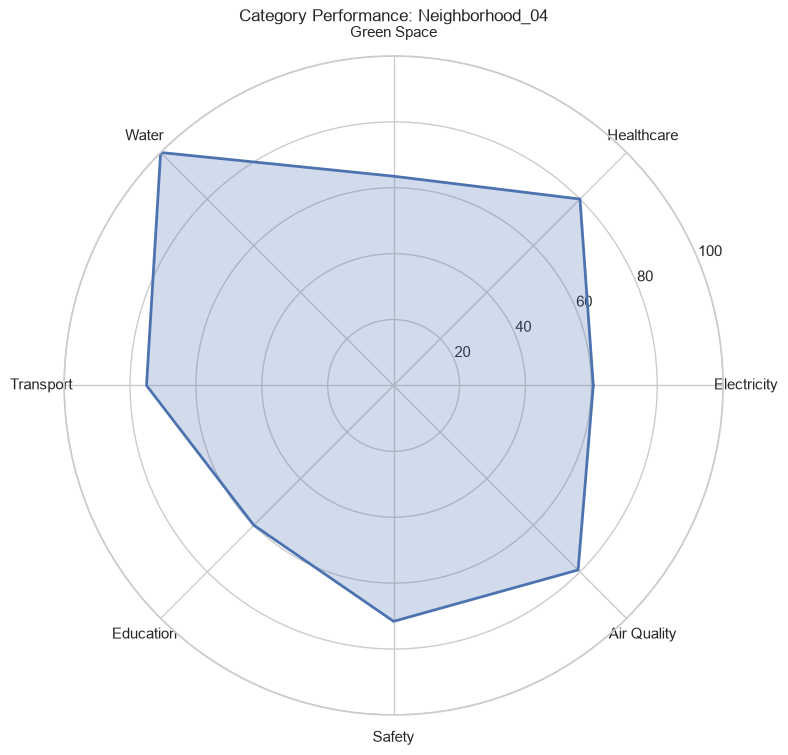

In [10]:
import numpy as np
import matplotlib.pyplot as plt

category_columns = [
    col for col in category_df.columns
    if col.endswith("_score")
]

selected = final_scores_df.iloc[0]

categories = [
    col.replace("_score", "")
    for col in category_columns
]

values = [
    selected[col]
    for col in category_columns
]

angles = np.linspace(
    0, 2 * np.pi, len(categories), endpoint=False
).tolist()

values += values[:1]
angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw=dict(polar=True)
)

ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.25)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

ax.set_ylim(0, 100)

plt.title(
    f"Category Performance: {selected['neighborhood_name']}",
    pad=25
)

plt.tight_layout()

plt.savefig(
    "screenshots/radar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


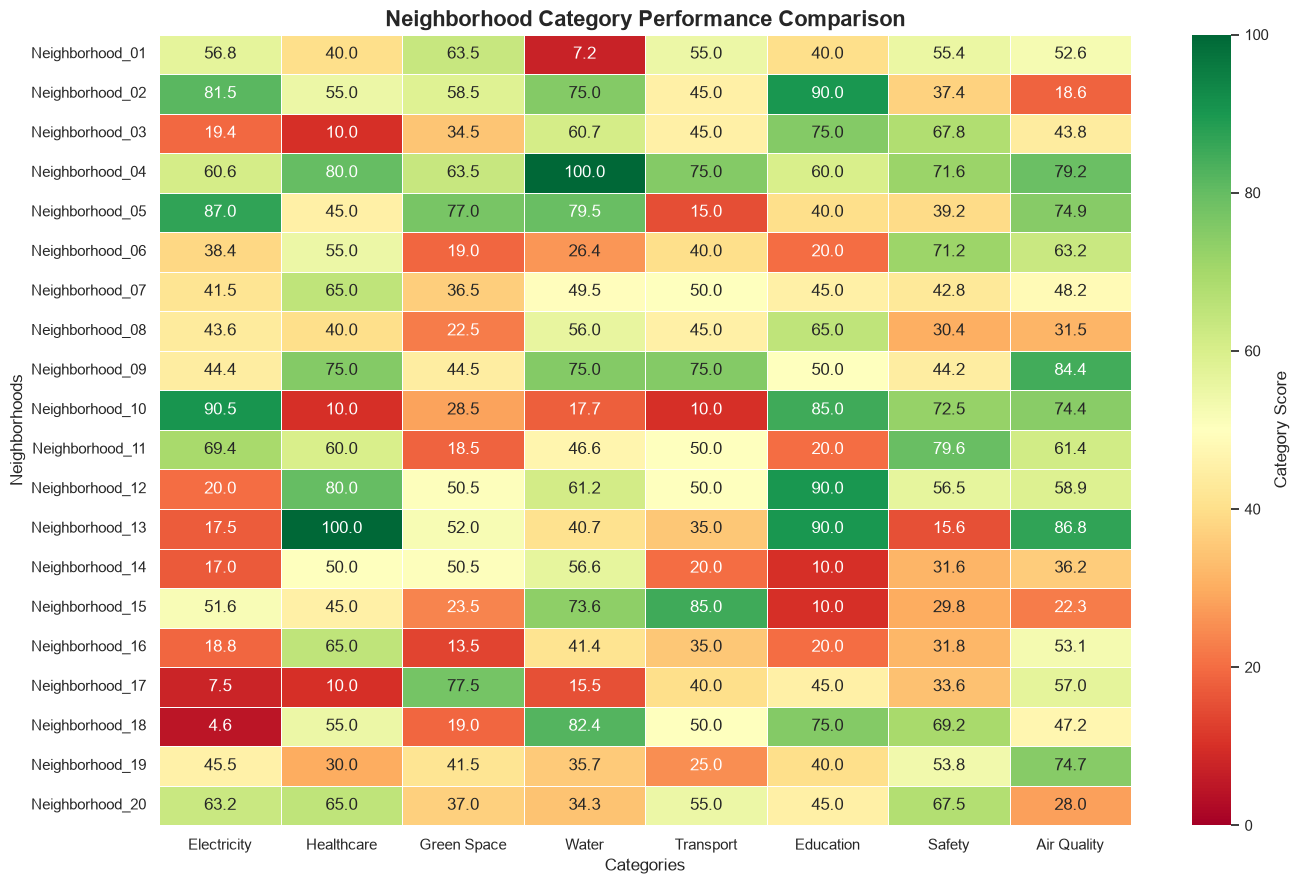

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

category_columns = [
    col for col in category_df.columns
    if col.endswith("_score")
]

heatmap_data = category_df.set_index(
    "neighborhood_name"
)[category_columns]

heatmap_data.columns = [
    col.replace("_score", "")
    for col in heatmap_data.columns
]

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Category Score"}
)

plt.title(
    "Neighborhood Category Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Categories")
plt.ylabel("Neighborhoods")

plt.tight_layout()

plt.savefig(
    "screenshots/heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


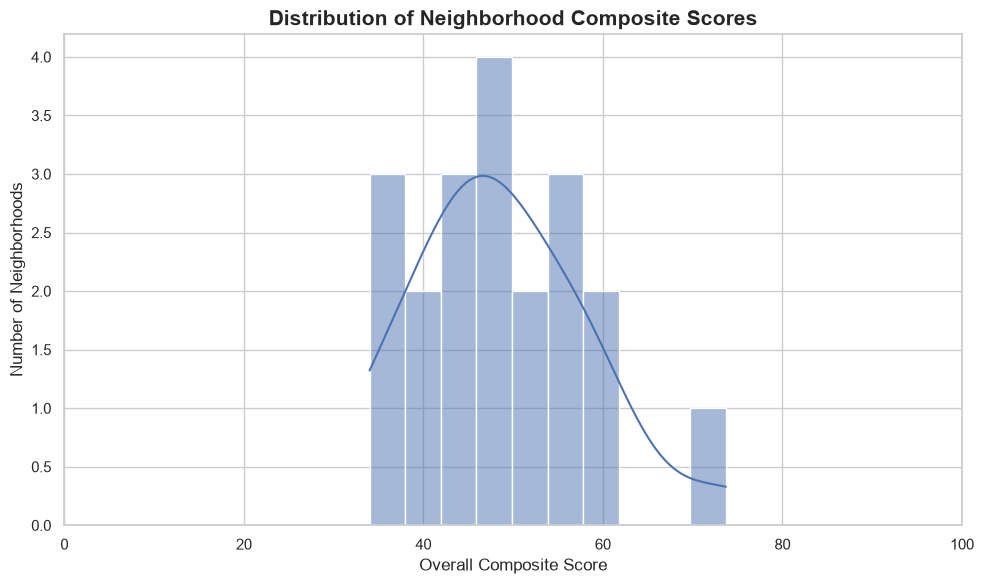

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

scores = final_scores_df["overall_score"]

plt.figure(figsize=(10, 6))

sns.histplot(
    scores,
    bins=10,
    kde=True
)

plt.title(
    "Distribution of Neighborhood Composite Scores",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Overall Composite Score")
plt.ylabel("Number of Neighborhoods")

plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "screenshots/score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
